# Garment condition: bigger subset, parallel download, AUC-focused training
**Before running:** Settings > Accelerator = **GPU T4 x2**, Internet = **On**.
Run cells in order. Cell 3 (download) is resumable: if the session dies, rerun it and it skips finished chunks.
Tip: after cell 3 finishes, save `/kaggle/working/cache` as a Kaggle Dataset ("Save Version" > output) so you never re-download.


In [1]:
!pip -q install remotezip

import os, json, random, hashlib, threading, time, io
import numpy as np, pandas as pd, requests
from concurrent.futures import ThreadPoolExecutor
from PIL import Image
from remotezip import RemoteZip

# ---------------- CONFIG ----------------
SEED         = 42
N_GARMENTS   = 12000      # raise to 16000+ if download is fast
IMG          = 256        # stored/training resolution
WORKERS      = 24         # parallel download threads
CHUNK        = 600        # garments per saved chunk (resume unit)
CACHE        = "/kaggle/working/cache"
os.makedirs(CACHE, exist_ok=True)
random.seed(SEED); np.random.seed(SEED)

import tensorflow as tf
print("TF", tf.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))


TF 2.20.0 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [2]:
!rm -f /kaggle/working/cache/*

In [3]:
# Resolve zip URL and index station1 garments
rec = requests.get("https://zenodo.org/api/records/12518734", timeout=30).json()
zip_url = next(f for f in rec["files"] if f["key"] == "circular_fashion_v2.zip")["links"]["self"]

with RemoteZip(zip_url) as z:
    names = z.namelist()

json_paths = [n for n in names
              if n.startswith("station1/") and "/json_errors/" not in n
              and "/labels_" in n and n.lower().endswith(".json")]
print("station1 labelled garments available:", len(json_paths))

rng = random.Random(SEED)
sel = rng.sample(json_paths, min(N_GARMENTS, len(json_paths)))
sel.sort()
print("selected:", len(sel))


station1 labelled garments available: 21900
selected: 12000


In [4]:
# PARALLEL DOWNLOAD + resize + cache in chunks (resumable)
import collections
tl = threading.local()
def get_zip(force=False):
    if force or not hasattr(tl, "z"):
        tl.z = RemoteZip(zip_url)
    return tl.z

def load_img(z, path):
    with z.open(path) as f:
        im = Image.open(io.BytesIO(f.read())).convert("RGB").resize((IMG, IMG), Image.BILINEAR)
    return np.asarray(im, dtype=np.uint8)

WORKERS = 8   # Zenodo throttles heavy parallelism; 6-10 is the sweet spot
errs = collections.Counter(); first_err = {}

def fetch(jp, retries=4):
    folder = os.path.dirname(jp)
    ts = os.path.basename(jp)[len("labels_"):-len(".json")]
    for attempt in range(retries + 1):
        try:
            z = get_zip(force=attempt > 0)
            with z.open(jp) as f:
                meta = json.load(f)
            for k in ("condition", "pilling", "stains", "holes"):
                if meta.get(k) is None or str(meta[k]).strip() == "":
                    errs["missing_label"] += 1
                    return None
            front = load_img(z, f"{folder}/front_{ts}.jpg")
            back  = load_img(z, f"{folder}/back_{ts}.jpg")
            return dict(id=folder.replace("/", "_") + "_" + ts,
                        condition=int(meta["condition"]), pilling=int(meta["pilling"]),
                        stains=str(meta["stains"]).strip().title(),
                        holes=str(meta["holes"]).strip().title(),
                        type=str(meta.get("type", "")).strip().title(),
                        front=front, back=back)
        except Exception as e:
            k = type(e).__name__
            errs[k] += 1; first_err.setdefault(k, str(e)[:200])
            time.sleep(1.5 * (attempt + 1))   # backoff
    errs["gave_up"] += 1
    return None

# quick sanity test on 8 garments before the long run
test = [fetch(p) for p in sel[:8]]
print("sanity test ok:", sum(r is not None for r in test), "/ 8 | errors:", dict(errs), first_err)

chunks = [sel[i:i + CHUNK] for i in range(0, len(sel), CHUNK)]
t0 = time.time()
with ThreadPoolExecutor(WORKERS) as ex:
    for ci, ch in enumerate(chunks):
        mp = f"{CACHE}/meta_{ci:03d}.csv"
        if os.path.exists(mp):
            continue
        res = [r for r in ex.map(fetch, ch) if r is not None]
        if not res:
            continue
        np.save(f"{CACHE}/front_{ci:03d}.npy", np.stack([r["front"] for r in res]))
        np.save(f"{CACHE}/back_{ci:03d}.npy",  np.stack([r["back"] for r in res]))
        pd.DataFrame([{k: v for k, v in r.items() if k not in ("front", "back")} for r in res]).to_csv(mp, index=False)
        print(f"chunk {ci+1}/{len(chunks)} ok ({len(res)}/{len(ch)}) | {time.time()-t0:.0f}s | errors so far: {dict(errs)}", flush=True)
print("download done")

sanity test ok: 8 / 8 | errors: {} {}
chunk 1/20 ok (526/600) | 1203s | errors so far: {'RemoteIOError': 766, 'gave_up': 74}


KeyboardInterrupt: 

In [5]:
import requests, struct, zlib, collections
from requests.adapters import HTTPAdapter

# one-time: locate byte offsets of the files we need (single index read)
need = set()
for jp in sel:
    d = os.path.dirname(jp); ts = os.path.basename(jp)[len("labels_"):-len(".json")]
    need.update([jp, f"{d}/front_{ts}.jpg", f"{d}/back_{ts}.jpg"])
with RemoteZip(zip_url) as z:
    infos = {i.filename: (i.header_offset, i.compress_size, i.compress_type)
             for i in z.infolist() if i.filename in need}
print(len(infos), "of", len(need), "entries located")

tl = threading.local()
def sess():
    if not hasattr(tl, "s"):
        s = requests.Session()
        s.mount("https://", HTTPAdapter(pool_connections=2, pool_maxsize=2))
        tl.s = s
    return tl.s

errs = collections.Counter(); first_err = {}
def read_member(path, tries=5):
    off, csize, ctype = infos[path]
    for a in range(tries):
        try:
            r = sess().get(zip_url, stream=True, timeout=60,
                           headers={"Range": f"bytes={off}-{off+csize+30+len(path.encode())+512}"})
            if r.status_code != 206:          # 206 only: a 200 would mean the whole 27GB
                r.close(); raise IOError(f"HTTP {r.status_code}")
            b = r.content
            n, m = struct.unpack("<HH", b[26:30])
            data = b[30+n+m : 30+n+m+csize]
            if len(data) != csize: raise IOError("short read")
            return data if ctype == 0 else zlib.decompress(data, -15)
        except Exception as e:
            k = type(e).__name__; errs[k] += 1; first_err.setdefault(k, str(e)[:150])
            time.sleep(min(1.5 * (a + 1), 6))
    raise IOError("gave up: " + path)

def load_img(path):
    return np.asarray(Image.open(io.BytesIO(read_member(path))).convert("RGB").resize((IMG, IMG), Image.BILINEAR), dtype=np.uint8)

def fetch(jp):
    folder = os.path.dirname(jp); ts = os.path.basename(jp)[len("labels_"):-len(".json")]
    try:
        meta = json.loads(read_member(jp))
        for k in ("condition", "pilling", "stains", "holes"):
            if meta.get(k) is None or str(meta[k]).strip() == "":
                errs["missing_label"] += 1; return None
        return dict(id=folder.replace("/", "_") + "_" + ts,
                    condition=int(meta["condition"]), pilling=int(meta["pilling"]),
                    stains=str(meta["stains"]).strip().title(), holes=str(meta["holes"]).strip().title(),
                    type=str(meta.get("type", "")).strip().title(),
                    front=load_img(f"{folder}/front_{ts}.jpg"), back=load_img(f"{folder}/back_{ts}.jpg"))
    except Exception as e:
        errs["gave_up"] += 1; return None

# timing test: this tells you the real speed before the long run
t = time.time(); test = [fetch(p) for p in sel[:6]]
print(f"test ok {sum(r is not None for r in test)}/6 in {time.time()-t:.1f}s | errors: {dict(errs)} {first_err}")

WORKERS = 12
chunks = [sel[i:i + CHUNK] for i in range(0, len(sel), CHUNK)]
t0 = time.time()
with ThreadPoolExecutor(WORKERS) as ex:
    for ci, ch in enumerate(chunks):
        mp = f"{CACHE}/meta_{ci:03d}.csv"
        if os.path.exists(mp): continue
        res = [r for r in ex.map(fetch, ch) if r is not None]
        if not res: continue
        np.save(f"{CACHE}/front_{ci:03d}.npy", np.stack([r["front"] for r in res]))
        np.save(f"{CACHE}/back_{ci:03d}.npy",  np.stack([r["back"] for r in res]))
        pd.DataFrame([{k: v for k, v in r.items() if k not in ("front", "back")} for r in res]).to_csv(mp, index=False)
        print(f"chunk {ci+1}/{len(chunks)} ok ({len(res)}/{len(ch)}) | {time.time()-t0:.0f}s | errors: {dict(errs)}", flush=True)
print("download done")

36000 of 36000 entries located
test ok 6/6 in 7.9s | errors: {} {}


KeyboardInterrupt: 

In [6]:
print("CPU cores:", os.cpu_count(), "| cache now:", sorted(os.listdir(CACHE))[:5])

def load_img(path):
    im = Image.open(io.BytesIO(read_member(path)))
    im.draft("RGB", (IMG * 2, IMG * 2))          # decode JPEG at 1/2, 1/4 or 1/8 size: big CPU saving
    im = im.convert("RGB").resize((IMG, IMG), Image.BILINEAR)
    return np.asarray(im, dtype=np.uint8)

# where does the time go?
p = sel[0]; folder = os.path.dirname(p); ts = os.path.basename(p)[len("labels_"):-len(".json")]
t = time.time(); raw = read_member(f"{folder}/front_{ts}.jpg"); t_dl = time.time() - t
t = time.time(); _ = load_img(f"{folder}/front_{ts}.jpg"); t_all = time.time() - t
print(f"one image: {len(raw)/1e6:.2f} MB | download ~{t_dl:.2f}s | download+decode {t_all:.2f}s")

WORKERS = 16
t0 = time.time()
with ThreadPoolExecutor(WORKERS) as ex:
    for ci, ch in enumerate(chunks):
        mp = f"{CACHE}/meta_{ci:03d}.csv"
        if os.path.exists(mp): continue
        res = []
        for i, r in enumerate(ex.map(fetch, ch), 1):
            if r is not None: res.append(r)
            if i % 100 == 0:
                print(f"   chunk {ci+1}: {i}/{len(ch)} | {time.time()-t0:.0f}s | errors {dict(errs)}", flush=True)
        if not res: continue
        np.save(f"{CACHE}/front_{ci:03d}.npy", np.stack([r["front"] for r in res]))
        np.save(f"{CACHE}/back_{ci:03d}.npy",  np.stack([r["back"] for r in res]))
        pd.DataFrame([{k: v for k, v in r.items() if k not in ("front", "back")} for r in res]).to_csv(mp, index=False)
        print(f"chunk {ci+1}/{len(chunks)} ok ({len(res)}/{len(ch)}) | {time.time()-t0:.0f}s", flush=True)
print("download done")

CPU cores: 4 | cache now: ['back_000.npy', 'front_000.npy', 'meta_000.csv']
one image: 0.22 MB | download ~1.14s | download+decode 0.32s
   chunk 2: 100/600 | 125s | errors {'OSError': 1758, 'gave_up': 193}
   chunk 2: 200/600 | 212s | errors {'OSError': 2073, 'gave_up': 224}
   chunk 2: 300/600 | 332s | errors {'OSError': 2486, 'gave_up': 253}
   chunk 2: 400/600 | 429s | errors {'OSError': 2820, 'gave_up': 280}
   chunk 2: 500/600 | 549s | errors {'OSError': 3239, 'gave_up': 314}
   chunk 2: 600/600 | 636s | errors {'OSError': 3526, 'gave_up': 346}
chunk 2/20 ok (412/600) | 636s
   chunk 3: 100/600 | 758s | errors {'OSError': 3942, 'gave_up': 370}
   chunk 3: 200/600 | 856s | errors {'OSError': 4278, 'gave_up': 394}
   chunk 3: 300/600 | 976s | errors {'OSError': 4694, 'gave_up': 426}
   chunk 3: 400/600 | 1096s | errors {'OSError': 5110, 'gave_up': 458}
   chunk 3: 500/600 | 1199s | errors {'OSError': 5462, 'gave_up': 490}
   chunk 3: 600/600 | 1301s | errors {'OSError': 5794, 'gave

In [7]:
   !du -sh /kaggle/working/cache

2.9G	/kaggle/working/cache


In [8]:
   !cd /kaggle/working && zip -r garment_cache.zip cache

  adding: cache/ (stored 0%)
  adding: cache/front_008.npy (deflated 39%)
  adding: cache/meta_007.csv (deflated 86%)
  adding: cache/front_012.npy (deflated 36%)
  adding: cache/meta_010.csv (deflated 86%)
  adding: cache/back_019.npy (deflated 39%)
  adding: cache/meta_012.csv (deflated 86%)
  adding: cache/meta_001.csv (deflated 86%)
  adding: cache/meta_015.csv (deflated 85%)
  adding: cache/meta_008.csv (deflated 86%)
  adding: cache/back_009.npy (deflated 38%)
  adding: cache/front_010.npy (deflated 36%)
  adding: cache/meta_016.csv (deflated 86%)
  adding: cache/front_013.npy (deflated 39%)
  adding: cache/back_016.npy (deflated 39%)
  adding: cache/front_004.npy (deflated 40%)
  adding: cache/front_014.npy (deflated 38%)
  adding: cache/back_014.npy (deflated 39%)
  adding: cache/back_018.npy (deflated 40%)
  adding: cache/back_007.npy (deflated 39%)
  adding: cache/front_019.npy (deflated 39%)
  adding: cache/back_000.npy (deflated 37%)
  adding: cache/back_001.npy (deflated 4

In [9]:
from IPython.display import FileLink

FileLink('/kaggle/working/garment_cache.zip')

/kaggle/working/garment_cache.zip

In [10]:
import os

path = "/kaggle/working/garment_cache.zip"

print("Exists:", os.path.exists(path))
if os.path.exists(path):
    print("Size:", round(os.path.getsize(path) / (1024**2), 2), "MB")

Exists: True
Size: 1770.31 MB


In [11]:
# Load cache, dedupe identical images, build simplified labels
metas, F, B = [], [], []
for mp in sorted(f for f in os.listdir(CACHE) if f.startswith("meta_")):
    ci = mp[5:8]
    metas.append(pd.read_csv(f"{CACHE}/{mp}", keep_default_na=False))
    F.append(np.load(f"{CACHE}/front_{ci}.npy")); B.append(np.load(f"{CACHE}/back_{ci}.npy"))
df = pd.concat(metas, ignore_index=True)
F = np.concatenate(F); B = np.concatenate(B)

# drop exact-duplicate garments (same front image bytes)
h = np.array([hashlib.md5(F[i].tobytes()).hexdigest() for i in range(len(F))])
keep = ~pd.Series(h).duplicated().values
df, F, B = df[keep].reset_index(drop=True), F[keep], B[keep]
print("garments after dedupe:", len(df))

# ---- simplified, more learnable targets ----
df["condition3"] = df["condition"].map({1: 0, 2: 0, 3: 1, 4: 2, 5: 2})    # poor / ok / good
df["pilling3"]   = df["pilling"].map({1: 0, 2: 0, 3: 0, 4: 1, 5: 2})
df["stains2"]    = (df["stains"].str.lower() != "none").astype(int)
df["holes2"]     = (df["holes"].str.lower()  != "none").astype(int)
df = df.dropna(subset=["condition3", "pilling3"]).copy()
F, B = F[df.index], B[df.index]; df = df.reset_index(drop=True)

# garment type as extra input (top 25 types, rest = other)
top = df["type"].value_counts().index[:25].tolist()
df["type_id"] = df["type"].apply(lambda t: top.index(t) + 1 if t in top else 0)
N_TYPES = len(top) + 1

TASKS = {"condition": ("condition3", 3), "pilling": ("pilling3", 3),
         "stains": ("stains2", 2), "holes": ("holes2", 2)}
for t, (c, k) in TASKS.items():
    print(t, df[c].value_counts().sort_index().to_dict())

from sklearn.model_selection import train_test_split
idx = np.arange(len(df))
tr, tmp = train_test_split(idx, test_size=0.30, random_state=SEED, stratify=df["condition3"])
va, te  = train_test_split(tmp, test_size=0.50, random_state=SEED, stratify=df.loc[tmp, "condition3"])
print("train/val/test:", len(tr), len(va), len(te))


garments after dedupe: 7658
condition {0: 1896, 1: 2560, 2: 3202}
pilling {0: 1808, 1: 1228, 2: 4622}
stains {0: 5393, 1: 2265}
holes {0: 7174, 1: 484}
train/val/test: 5360 1149 1149


In [12]:
# tf.data pipelines (arrays live in RAM; per-sample generator keeps graph small)
from sklearn.utils.class_weight import compute_class_weight
BATCH_PER_GPU = 32
strategy = tf.distribute.MirroredStrategy()
GBATCH = BATCH_PER_GPU * strategy.num_replicas_in_sync
print("replicas:", strategy.num_replicas_in_sync, "| global batch:", GBATCH)

Y = {t: df[c].values.astype("int32") for t, (c, k) in TASKS.items()}
T = df["type_id"].values.astype("int32")

# gentle class weights from the TRAIN split only
CW = {}
for t, (c, k) in TASKS.items():
    cnt = np.bincount(Y[t][tr], minlength=k).astype("float32")
    w = np.sqrt(len(tr) / (k * np.maximum(cnt, 1))); w = np.clip(w, 0.6, 2.5)
    CW[t] = (w / np.average(w, weights=np.maximum(cnt, 1))).astype("float32")

SIG_X = {"front": tf.TensorSpec((IMG, IMG, 3), tf.uint8),
         "back":  tf.TensorSpec((IMG, IMG, 3), tf.uint8),
         "type":  tf.TensorSpec((), tf.int32)}
SIG_Y = {t: tf.TensorSpec((), tf.int32) for t in TASKS}
SIG_W = {t: tf.TensorSpec((), tf.float32) for t in TASKS}

def make_ds(ids, train=False, labels=True):
    ids = np.array(ids)
    def gen():
        order = np.random.permutation(ids) if train else ids
        for i in order:
            x = {"front": F[i], "back": B[i], "type": T[i]}
            if not labels:
                yield x
            elif train:
                yield x, {t: Y[t][i] for t in TASKS}, {t: CW[t][Y[t][i]] for t in TASKS}
            else:
                yield x, {t: Y[t][i] for t in TASKS}
    sig = SIG_X if not labels else ((SIG_X, SIG_Y, SIG_W) if train else (SIG_X, SIG_Y))
    ds = tf.data.Dataset.from_generator(gen, output_signature=sig)

    def prep(x, *rest):
        f, b = tf.cast(x["front"], tf.float32), tf.cast(x["back"], tf.float32)
        if train:
            if tf.random.uniform(()) < 0.5: f = tf.image.flip_left_right(f)
            if tf.random.uniform(()) < 0.5: b = tf.image.flip_left_right(b)
            f = tf.clip_by_value(tf.image.random_brightness(f, 25.0), 0, 255)
            b = tf.clip_by_value(tf.image.random_brightness(b, 25.0), 0, 255)
            f = tf.image.random_contrast(f, 0.85, 1.15); b = tf.image.random_contrast(b, 0.85, 1.15)
        x = {"front": f, "back": b, "type": x["type"]}
        return (x, *rest)
    ds = ds.map(prep, num_parallel_calls=tf.data.AUTOTUNE).batch(GBATCH).prefetch(tf.data.AUTOTUNE)
    opt = tf.data.Options(); opt.experimental_distribute.auto_shard_policy = tf.data.experimental.AutoShardPolicy.OFF
    return ds.with_options(opt)

train_ds, val_ds = make_ds(tr, True), make_ds(va)


INFO:tensorflow:Using MirroredStrategy with devices ('/job:localhost/replica:0/task:0/device:GPU:0', '/job:localhost/replica:0/task:0/device:GPU:1')


I0000 00:00:1793027485.575104     198 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1793027485.580227     198 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


replicas: 2 | global batch: 64


In [13]:
# Model: shared EfficientNetB0 on front+back, plus garment-type embedding
from tensorflow.keras import layers, Model, mixed_precision
mixed_precision.set_global_policy("mixed_float16")

with strategy.scope():
    fin = layers.Input((IMG, IMG, 3), name="front")
    bin_ = layers.Input((IMG, IMG, 3), name="back")
    tin = layers.Input((), dtype="int32", name="type")

    backbone = tf.keras.applications.EfficientNetB0(include_top=False, weights="imagenet",
                                                    input_shape=(IMG, IMG, 3), pooling="avg")
    backbone.trainable = False
    ff = backbone(fin, training=False)
    fb = backbone(bin_, training=False)
    te_ = layers.Flatten()(layers.Embedding(N_TYPES, 16)(tin))

    x = layers.Concatenate()([ff, fb, te_])
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    outs = {t: layers.Dense(k, activation="softmax", dtype="float32", name=t)(x) for t, (c, k) in TASKS.items()}
    model = Model([fin, bin_, tin], outs)

    LOSS_W = {"condition": 2.0, "pilling": 1.0, "stains": 1.0, "holes": 1.0}
    def compile_(lr):
        model.compile(tf.keras.optimizers.Adam(lr),
                      loss={t: "sparse_categorical_crossentropy" for t in TASKS},
                      loss_weights=LOSS_W,
                      metrics={t: ["accuracy"] for t in TASKS})
    compile_(1e-3)


16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [14]:
# PHASE 1: train the heads (backbone frozen)
WEIGHTS = "/kaggle/working/best.weights.h5"
cbs = lambda: [
    tf.keras.callbacks.ModelCheckpoint(WEIGHTS, monitor="val_loss", save_best_only=True,
                                       save_weights_only=True, verbose=1),
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.4, patience=2, min_lr=1e-7, verbose=1),
]
h1 = model.fit(train_ds, validation_data=val_ds, epochs=6, callbacks=cbs())


INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Redu

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 1: val_loss improved from None to 4.11833, saving model to /kaggle/working/best.weights.h5

Epoch 1: finished saving model to /kaggle/working/best.weights.h5
84/84 ━━━━━━━━━━━━━━━━━━━━ 144s 1s/step - condition_accuracy: 0.3916 - condition_loss: 1.1036 - holes_accuracy: 0.9215 - holes_loss: 0.5078 - loss: 4.4982 - pilling_accuracy: 0.5336 - pilling_loss: 1.0751 - stains_accuracy: 0.6698 - stains_loss: 0.6550 - val_condition_accuracy: 0.4178 - val_condition_loss: 1.0040 - val_holes_accuracy: 0.9469 - val_holes_loss: 0.3511 - val_loss: 4.1183 - val_pilling_accuracy: 0.5840 - val_pilling_loss: 0.9516 - val_stains_accuracy: 0.6728 - val_stains_loss: 0.5903 - learning_rate: 0.0010
Epoch 2/6
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 163ms/step - condition_accuracy: 0.4067 - condition_loss: 1.0836 - holes_accuracy: 0.9402 - holes_loss: 0.4585 - loss: 4.3202 - pilling_accuracy: 0.5551 - pilling_loss: 1.0563 - stains_accuracy: 0.6910 - stains_loss: 0.6381
Epoch 2: val_loss improved from 4.11833 to 4.

In [15]:
# PHASE 2: fine-tune top of backbone (BatchNorm stays frozen)
with strategy.scope():
    backbone.trainable = True
    for l in backbone.layers[:-120]:
        l.trainable = False
    for l in backbone.layers:
        if isinstance(l, layers.BatchNormalization):
            l.trainable = False
    compile_(1e-4)
print("trainable backbone layers:", sum(l.trainable for l in backbone.layers))
h2 = model.fit(train_ds, validation_data=val_ds, epochs=30, callbacks=cbs())


trainable backbone layers: 95
Epoch 1/30
INFO:tensorflow:Collective all_reduce tensors: 67 all_reduces, num_devices = 2, group_size = 2, implementation = CommunicationImplementation.NCCL, num_packs = 1
INFO:tensorflow:Collective all_reduce IndexedSlices: 1 all_reduces, num_devices =2, group_size = 2, implementation = CommunicationImplementation.NCCL
     84/Unknown 97s 488ms/step - condition_accuracy: 0.4820 - condition_loss: 1.0239 - holes_accuracy: 0.9270 - holes_loss: 0.4400 - loss: 4.0820 - pilling_accuracy: 0.6023 - pilling_loss: 0.9921 - stains_accuracy: 0.7102 - stains_loss: 0.6021
Epoch 1: val_loss improved from None to 3.90601, saving model to /kaggle/working/best.weights.h5

Epoch 1: finished saving model to /kaggle/working/best.weights.h5
84/84 ━━━━━━━━━━━━━━━━━━━━ 113s 680ms/step - condition_accuracy: 0.4718 - condition_loss: 1.0152 - holes_accuracy: 0.9265 - holes_loss: 0.4462 - loss: 4.1036 - pilling_accuracy: 0.5950 - pilling_loss: 0.9856 - stains_accuracy: 0.7146 - stai

In [18]:
# EVALUATION: one-vs-rest AUC-ROC per task (+ flip TTA)
from sklearn.metrics import roc_auc_score, classification_report, confusion_matrix
model.load_weights(WEIGHTS)

def predict(ids, flip=False):
    ds = make_ds(ids, False, labels=False)
    if flip:
        ds = ds.map(lambda x: {"front": tf.image.flip_left_right(x["front"]),
                               "back": tf.image.flip_left_right(x["back"]), "type": x["type"]})
    return model.predict(ds, verbose=0)

def evaluate(ids, name):
    p0, p1 = predict(ids), predict(ids, True)
    aucs = {}
    for t, (c, k) in TASKS.items():
        y, p = Y[t][ids], (p0[t] + p1[t]) / 2
        if k == 2:
            aucs[t] = roc_auc_score(y, p[:, 1])
        else:
            present = np.unique(y)
            aucs[t] = roc_auc_score(y, p[:, present] / p[:, present].sum(1, keepdims=True),
                                    multi_class="ovr", average="macro", labels=present)
        print(f"\n[{name}] {t}: AUC={aucs[t]:.3f}")
        print(classification_report(y, p.argmax(1), zero_division=0, digits=3))
    print(f"\n[{name}] MEAN AUC = {np.mean(list(aucs.values())):.3f}")
    return aucs

val_auc  = evaluate(va, "val")
test_auc = evaluate(te, "test")


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



[val] condition: AUC=0.638
              precision    recall  f1-score   support

           0      0.371     0.363     0.367       284
           1      0.426     0.240     0.307       384
           2      0.515     0.701     0.593       481

    accuracy                          0.463      1149
   macro avg      0.437     0.434     0.422      1149
weighted avg      0.449     0.463     0.441      1149


[val] pilling: AUC=0.647
              precision    recall  f1-score   support

           0      0.406     0.284     0.334       257
           1      0.326     0.075     0.122       199
           2      0.660     0.879     0.754       693

    accuracy                          0.607      1149
   macro avg      0.464     0.413     0.403      1149
weighted avg      0.545     0.607     0.551      1149


[val] stains: AUC=0.693
              precision    recall  f1-score   support

           0      0.745     0.854     0.795       779
           1      0.555     0.384     0.454       

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



[test] condition: AUC=0.636
              precision    recall  f1-score   support

           0      0.381     0.344     0.362       285
           1      0.464     0.286     0.354       384
           2      0.518     0.706     0.597       480

    accuracy                          0.476      1149
   macro avg      0.454     0.446     0.438      1149
weighted avg      0.466     0.476     0.458      1149


[test] pilling: AUC=0.649
              precision    recall  f1-score   support

           0      0.465     0.248     0.324       290
           1      0.244     0.058     0.094       171
           2      0.653     0.904     0.758       688

    accuracy                          0.613      1149
   macro avg      0.454     0.404     0.392      1149
weighted avg      0.544     0.613     0.550      1149


[test] stains: AUC=0.728
              precision    recall  f1-score   support

           0      0.791     0.853     0.821       821
           1      0.542     0.436     0.483    

In [17]:
# Save final artifacts
model.save("/kaggle/working/garment_model.keras")
pd.DataFrame({"val_auc": val_auc, "test_auc": test_auc}).to_csv("/kaggle/working/auc_results.csv")
print(pd.DataFrame({"val_auc": val_auc, "test_auc": test_auc}).round(3))


           val_auc  test_auc
condition    0.638     0.636
pilling      0.647     0.649
stains       0.693     0.728
holes        0.633     0.614


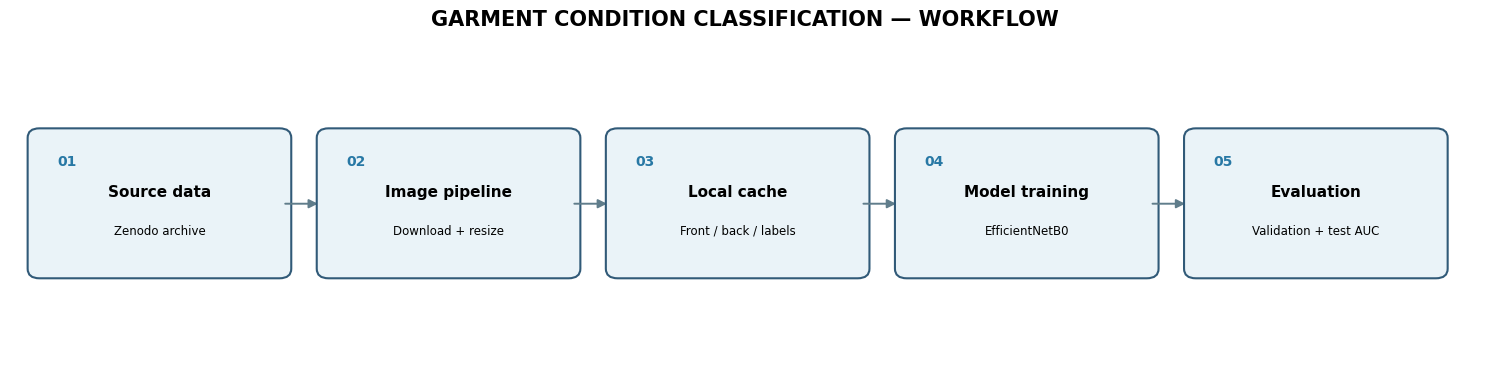

In [19]:

# VISUAL 1 — PROJECT WORKFLOW
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

def workflow_diagram():
    fig, ax = plt.subplots(figsize=(15, 3.8))
    ax.set_xlim(0, 15)
    ax.set_ylim(0, 4)
    ax.axis("off")

    steps = [
        ("01", "Source data", "Zenodo archive"),
        ("02", "Image pipeline", "Download + resize"),
        ("03", "Local cache", "Front / back / labels"),
        ("04", "Model training", "EfficientNetB0"),
        ("05", "Evaluation", "Validation + test AUC"),
    ]
    xs = [0.3, 3.25, 6.2, 9.15, 12.1]

    for i, (num, title, subtitle) in enumerate(steps):
        x = xs[i]
        box = FancyBboxPatch(
            (x, 1.15), 2.45, 1.65,
            boxstyle="round,pad=0.12",
            linewidth=1.5, edgecolor="#315A78",
            facecolor="#EAF3F8"
        )
        ax.add_patch(box)
        ax.text(x + 0.18, 2.45, num, fontsize=10,
                color="#2878A5", weight="bold")
        ax.text(x + 1.225, 2.05, title, ha="center",
                fontsize=11, weight="bold")
        ax.text(x + 1.225, 1.58, subtitle, ha="center",
                fontsize=8.5)
        if i < len(steps) - 1:
            ax.add_patch(FancyArrowPatch(
                (x + 2.48, 1.97), (xs[i+1] - 0.08, 1.97),
                arrowstyle="-|>", mutation_scale=13,
                linewidth=1.4, color="#607D8B"
            ))

    ax.set_title("GARMENT CONDITION CLASSIFICATION — WORKFLOW",
                 fontsize=15, weight="bold", pad=12)
    plt.tight_layout()
    plt.show()

workflow_diagram()


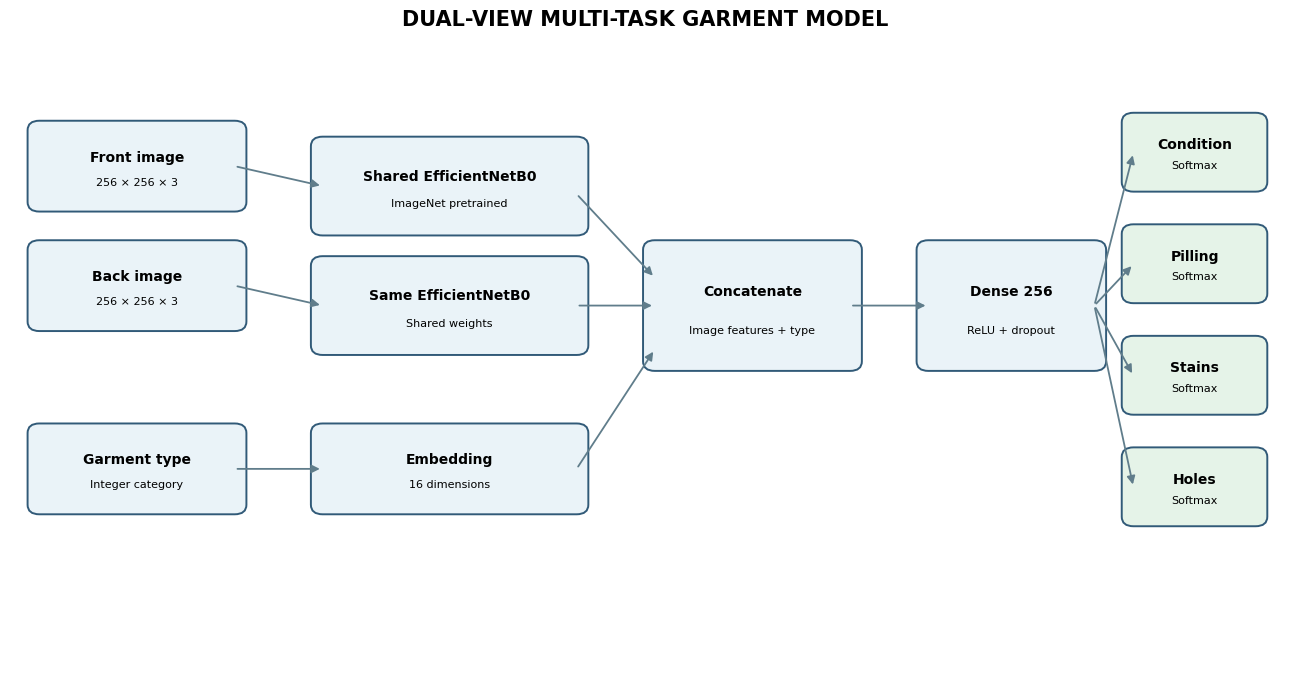

In [20]:

# VISUAL 2 — MODEL ARCHITECTURE
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

def model_architecture():
    fig, ax = plt.subplots(figsize=(13, 7))
    ax.set_xlim(0, 13)
    ax.set_ylim(0, 8)
    ax.axis("off")

    def box(x, y, w, h, title, subtitle="", color="#EAF3F8"):
        patch = FancyBboxPatch(
            (x, y), w, h, boxstyle="round,pad=0.12",
            facecolor=color, edgecolor="#315A78", linewidth=1.4
        )
        ax.add_patch(patch)
        ax.text(x+w/2, y+h*0.62, title, ha="center",
                va="center", fontsize=10, weight="bold")
        if subtitle:
            ax.text(x+w/2, y+h*0.27, subtitle, ha="center",
                    va="center", fontsize=8)

    def arrow(a, b):
        ax.add_patch(FancyArrowPatch(
            a, b, arrowstyle="-|>", mutation_scale=12,
            linewidth=1.3, color="#607D8B"
        ))

    box(0.3, 6.0, 2.0, 0.9, "Front image", "256 × 256 × 3")
    box(0.3, 4.5, 2.0, 0.9, "Back image", "256 × 256 × 3")
    box(0.3, 2.2, 2.0, 0.9, "Garment type", "Integer category")

    box(3.2, 5.7, 2.6, 1.0, "Shared EfficientNetB0", "ImageNet pretrained")
    box(3.2, 4.2, 2.6, 1.0, "Same EfficientNetB0", "Shared weights")
    box(3.2, 2.2, 2.6, 0.9, "Embedding", "16 dimensions")

    arrow((2.3, 6.45), (3.2, 6.2))
    arrow((2.3, 4.95), (3.2, 4.7))
    arrow((2.3, 2.65), (3.2, 2.65))

    box(6.6, 4.0, 2.0, 1.4, "Concatenate", "Image features + type")
    arrow((5.8, 6.1), (6.6, 5.05))
    arrow((5.8, 4.7), (6.6, 4.7))
    arrow((5.8, 2.65), (6.6, 4.15))

    box(9.4, 4.0, 1.7, 1.4, "Dense 256", "ReLU + dropout")
    arrow((8.6, 4.7), (9.4, 4.7))

    heads = [
        ("Condition", 6.25),
        ("Pilling", 4.85),
        ("Stains", 3.45),
        ("Holes", 2.05),
    ]
    for name, y in heads:
        box(11.5, y, 1.25, 0.75, name, "Softmax",
            color="#E5F3E8")
        arrow((11.1, 4.7), (11.5, y+0.37))

    ax.set_title("DUAL-VIEW MULTI-TASK GARMENT MODEL",
                 fontsize=15, weight="bold", pad=12)
    plt.tight_layout()
    plt.show()

model_architecture()


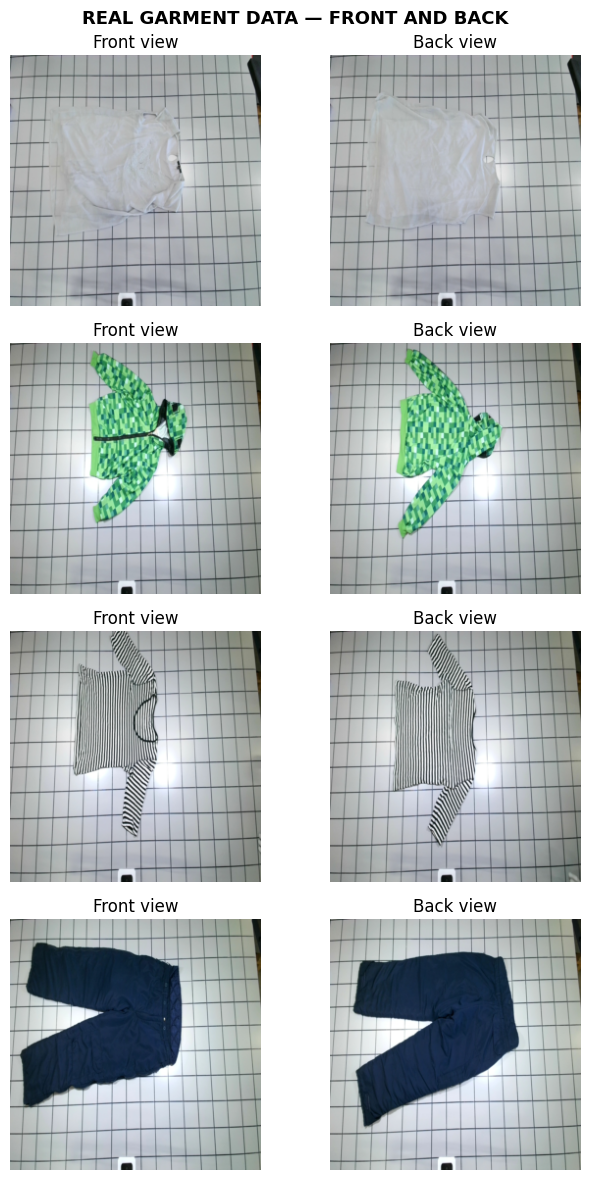

In [21]:

# VISUAL 3 — REAL FRONT/BACK GARMENT EXAMPLES
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

CACHE = "/kaggle/working/cache"

meta_files = sorted(glob.glob(f"{CACHE}/meta_*.csv"))
shown = False

for mp in meta_files:
    chunk_id = os.path.basename(mp).replace("meta_", "").replace(".csv", "")
    fp = f"{CACHE}/front_{chunk_id}.npy"
    bp = f"{CACHE}/back_{chunk_id}.npy"

    if not (os.path.exists(fp) and os.path.exists(bp)):
        continue

    meta = pd.read_csv(mp, keep_default_na=False)
    front = np.load(fp, mmap_mode="r")
    back = np.load(bp, mmap_mode="r")

    n = min(4, len(meta), len(front), len(back))
    if n == 0:
        continue

    fig, axes = plt.subplots(n, 2, figsize=(7, 3*n))
    if n == 1:
        axes = np.array([axes])

    for i in range(n):
        axes[i, 0].imshow(front[i])
        axes[i, 0].set_title("Front view")
        axes[i, 1].imshow(back[i])
        axes[i, 1].set_title("Back view")

        for ax in axes[i]:
            ax.axis("off")

        row = meta.iloc[i]
        label = (
            f"Condition: {row.get('condition', 'N/A')} | "
            f"Pilling: {row.get('pilling', 'N/A')} | "
            f"Stains: {row.get('stains', 'N/A')} | "
            f"Holes: {row.get('holes', 'N/A')}"
        )
        axes[i, 0].set_ylabel(label, fontsize=8)

    fig.suptitle("REAL GARMENT DATA — FRONT AND BACK",
                 fontsize=13, weight="bold")
    plt.tight_layout()
    plt.show()
    shown = True
    break

if not shown:
    print("No complete image chunk found in the cache.")


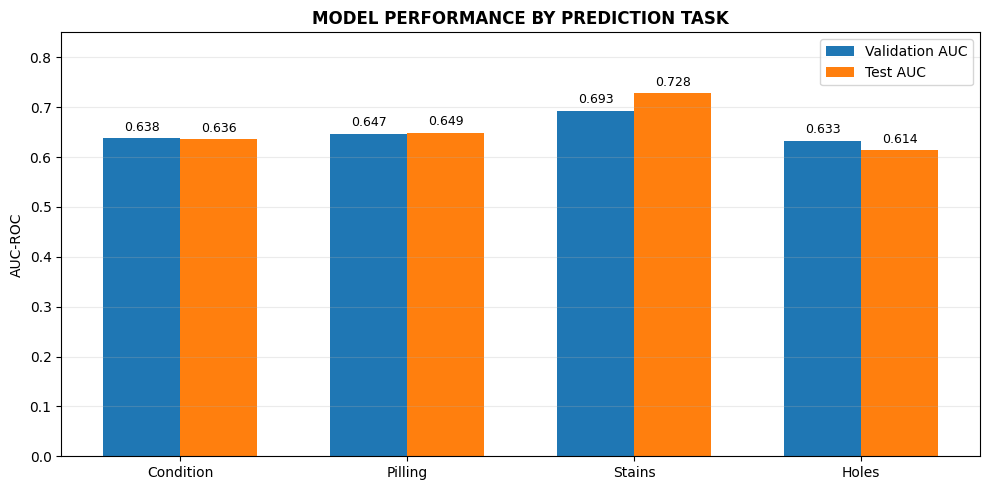

Mean validation AUC: 0.653
Mean test AUC: 0.657


In [22]:

# VISUAL 4A — RECORDED AUC RESULTS
import numpy as np
import matplotlib.pyplot as plt

tasks = ["Condition", "Pilling", "Stains", "Holes"]
val_auc = [0.638, 0.647, 0.693, 0.633]
test_auc = [0.636, 0.649, 0.728, 0.614]

x = np.arange(len(tasks))
width = 0.34

fig, ax = plt.subplots(figsize=(10, 5))
b1 = ax.bar(x-width/2, val_auc, width, label="Validation AUC")
b2 = ax.bar(x+width/2, test_auc, width, label="Test AUC")

ax.bar_label(b1, fmt="%.3f", padding=3, fontsize=9)
ax.bar_label(b2, fmt="%.3f", padding=3, fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels(tasks)
ax.set_ylim(0, 0.85)
ax.set_ylabel("AUC-ROC")
ax.set_title("MODEL PERFORMANCE BY PREDICTION TASK",
             weight="bold")
ax.legend()
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

print("Mean validation AUC:", round(np.mean(val_auc), 3))
print("Mean test AUC:", round(np.mean(test_auc), 3))


Rows read from cached metadata: 7,680


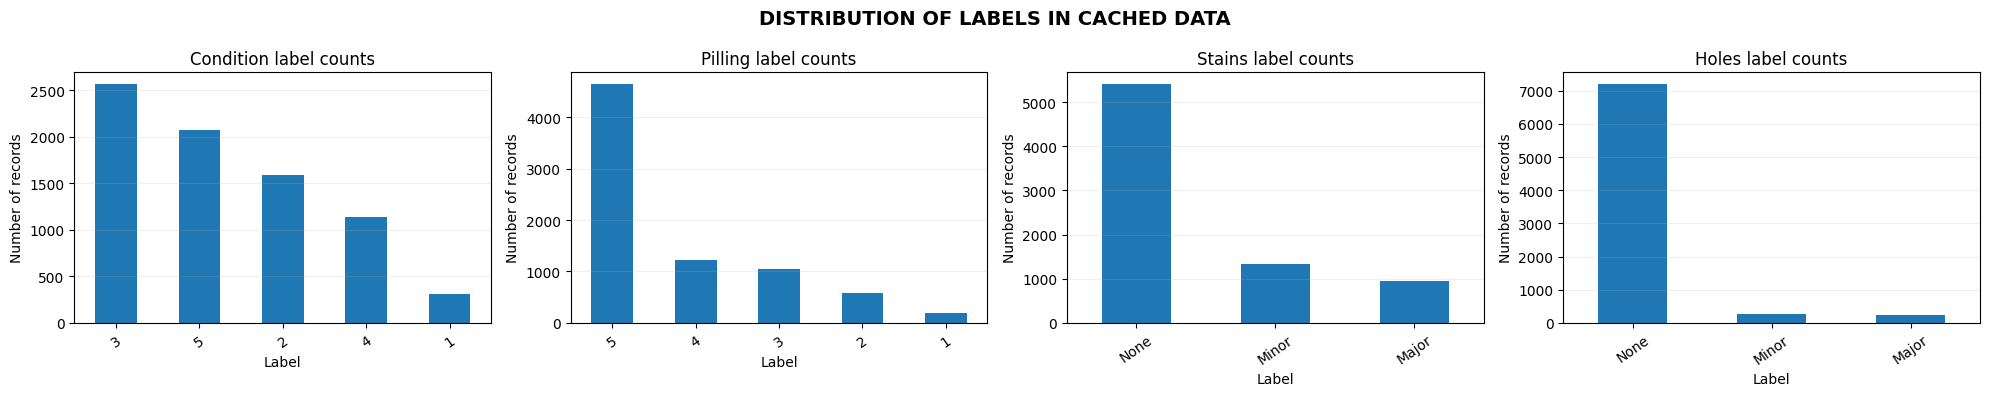

In [23]:

# VISUAL 4B — ACTUAL CACHED LABEL DISTRIBUTIONS
import glob
import os
import pandas as pd
import matplotlib.pyplot as plt

CACHE = "/kaggle/working/cache"
meta_files = sorted(glob.glob(f"{CACHE}/meta_*.csv"))

if not meta_files:
    print("No metadata CSV files found in the cache.")
else:
    frames = []
    for path in meta_files:
        df = pd.read_csv(path, keep_default_na=False)
        frames.append(df)

    metadata = pd.concat(frames, ignore_index=True)
    print(f"Rows read from cached metadata: {len(metadata):,}")

    # Plot only columns that actually exist in the cache.
    candidates = ["condition", "pilling", "stains", "holes"]
    columns = [c for c in candidates if c in metadata.columns]

    if not columns:
        print("No expected label columns found.")
        print("Available columns:", metadata.columns.tolist())
    else:
        fig, axes = plt.subplots(
            1, len(columns),
            figsize=(5 * len(columns), 4)
        )
        if len(columns) == 1:
            axes = [axes]

        for ax, col in zip(axes, columns):
            counts = metadata[col].astype(str).value_counts()
            counts.plot(kind="bar", ax=ax)
            ax.set_title(f"{col.title()} label counts")
            ax.set_xlabel("Label")
            ax.set_ylabel("Number of records")
            ax.tick_params(axis="x", rotation=35)
            ax.grid(axis="y", alpha=0.2)

        fig.suptitle("DISTRIBUTION OF LABELS IN CACHED DATA",
                     fontsize=14, weight="bold")
        plt.tight_layout()
        plt.show()


# Improving Results


In [24]:
import os, glob, hashlib, time, numpy as np, pandas as pd
CACHE = "/kaggle/working/cache"          # or "/kaggle/input/<your-dataset>/cache"
metas, F, B = [], [], []
for mp in sorted(glob.glob(f"{CACHE}/meta_*.csv")):
    k = os.path.basename(mp)[5:-4]
    metas.append(pd.read_csv(mp, keep_default_na=False))      # keep "None" as a string, not NaN
    F.append(np.load(f"{CACHE}/front_{k}.npy")); B.append(np.load(f"{CACHE}/back_{k}.npy"))
df = pd.concat(metas, ignore_index=True); F = np.concatenate(F); B = np.concatenate(B)
keep = ~pd.Series([hashlib.md5(f.tobytes()).hexdigest() for f in F]).duplicated().values
df, F, B = df[keep].reset_index(drop=True), F[keep], B[keep]
df = df[df.condition.between(1, 5) & df.pilling.between(1, 5)]
F, B = F[df.index], B[df.index]; df = df.reset_index(drop=True)
df["condition3"] = df.condition.map({1: 0, 2: 0, 3: 1, 4: 2, 5: 2})
df["pilling3"]   = df.pilling.map({1: 0, 2: 0, 3: 0, 4: 1, 5: 2})
df["stains2"]    = (df.stains.astype(str).str.title() != "None").astype(int)
df["holes2"]     = (df.holes.astype(str).str.title() != "None").astype(int)
top = df.type.value_counts().index[:25]
df["type_id"] = df.type.map({t: i + 1 for i, t in enumerate(top)}).fillna(0).astype(int)
print("garments:", len(df), "| images", F.shape)
for c in ("condition3", "pilling3", "stains2", "holes2"): print(c, df[c].value_counts(normalize=True).round(2).to_dict())

garments: 7658 | images (7658, 256, 256, 3)
condition3 {2: 0.42, 1: 0.33, 0: 0.25}
pilling3 {2: 0.6, 0: 0.24, 1: 0.16}
stains2 {0: 0.7, 1: 0.3}
holes2 {0: 0.94, 1: 0.06}


## Embeddings from DINOv2 and CLIP, with flip averaging

In [25]:
import torch
from transformers import AutoModel, CLIPModel
dev = "cuda"
MEAN = {"dino": (0.485, 0.456, 0.406), "clip": (0.4815, 0.4578, 0.4082)}
STD  = {"dino": (0.229, 0.224, 0.225), "clip": (0.2686, 0.2613, 0.2758)}

@torch.no_grad()
def embed(name, imgs, size, tag, bs=96):
    path = f"/kaggle/working/emb_{name.split('/')[-1]}_{size}_{tag}_{len(imgs)}.npy"
    if os.path.exists(path): return np.load(path)
    kind = "clip" if "clip" in name else "dino"
    m = (CLIPModel if kind == "clip" else AutoModel).from_pretrained(name, torch_dtype=torch.float16).to(dev).eval()
    mean = torch.tensor(MEAN[kind], device=dev).view(1, 3, 1, 1); std = torch.tensor(STD[kind], device=dev).view(1, 3, 1, 1)
    outs = []
    for i in range(0, len(imgs), bs):
        x = torch.from_numpy(np.ascontiguousarray(imgs[i:i + bs])).to(dev).permute(0, 3, 1, 2).float() / 255
        x = torch.nn.functional.interpolate(x, size=(size, size), mode="bilinear", antialias=True, align_corners=False)
        x = ((x - mean) / std).half(); fs = []
        for xx in (x, x.flip(-1)):                       # flip TTA, averaged
            if kind == "clip":
                f = m.get_image_features(pixel_values=xx)
                if not torch.is_tensor(f): f = f.pooler_output
            else:
                h = m(pixel_values=xx).last_hidden_state
                f = torch.cat([h[:, 0], h[:, 1:].mean(1)], 1)   # CLS + mean patch token
            fs.append(f.float())
        outs.append(((fs[0] + fs[1]) / 2).cpu().numpy())
    del m; torch.cuda.empty_cache()
    E = np.concatenate(outs); np.save(path, E); return E

EMB = {}
for name, size in [("facebook/dinov2-base", 252), ("openai/clip-vit-base-patch16", 224), ("facebook/dinov2-large", 252)]:
    t = time.time()
    for view, imgs in (("front", F), ("back", B)):
        EMB[(name.split("/")[-1], view)] = embed(name, imgs, size, view)
    print(name, "done in", round(time.time() - t), "s")

config.json:   0%|          | 0.00/548 [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.22GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/439 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/439 [00:00<?, ?it/s]

facebook/dinov2-large done in 461 s


## Near-duplicate groups and leak-proof folds

In [26]:
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold
Z = EMB[("dinov2-base", "front")][:, :768].astype(np.float32); Z /= np.linalg.norm(Z, axis=1, keepdims=True)
S = Z @ Z.T; np.fill_diagonal(S, 0)
for thr in (0.99, 0.97, 0.95, 0.92): print(f"pairs with cosine > {thr}: {(S > thr).sum() // 2}")
for THR in (0.95, 0.97, 0.98, 0.99):
    _, groups = connected_components(csr_matrix(S > THR), directed=False)
    if np.bincount(groups).max() <= 30: break
print(f"near-duplicate threshold {THR}: {groups.max() + 1} groups for {len(df)} garments, largest group {np.bincount(groups).max()}")
del S
y_strat = df.condition3.values
folds = list(StratifiedGroupKFold(5, shuffle=True, random_state=42).split(np.zeros(len(df)), y_strat, groups))
folds_naive = list(StratifiedKFold(5, shuffle=True, random_state=42).split(np.zeros(len(df)), y_strat))

pairs with cosine > 0.99: 0
pairs with cosine > 0.97: 169
pairs with cosine > 0.95: 3686
pairs with cosine > 0.92: 25099
near-duplicate threshold 0.98: 7654 groups for 7658 garments, largest group 3


## Features and classifier heads

In [27]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import roc_auc_score
import lightgbm as lgb

TASKS = {"condition": ("condition3", 3), "pilling": ("pilling3", 3), "stains": ("stains2", 2), "holes": ("holes2", 2)}
onehot = np.eye(26, dtype=np.float32)[df.type_id.values]

def pca_feats(parts, n=256):
    X = StandardScaler().fit_transform(np.concatenate(parts, 1))
    return PCA(min(n, X.shape[1], X.shape[0] - 1), random_state=0).fit_transform(X).astype(np.float32)

FEATS = {}
for m in sorted({k[0] for k in EMB}):
    FEATS[m] = np.c_[pca_feats([EMB[(m, "front")], EMB[(m, "back")]]), onehot]
FEATS["all"] = np.c_[pca_feats([EMB[k] for k in sorted(EMB)], 384), onehot]
print({k: v.shape for k, v in FEATS.items()})

def auc(y, P):
    P = np.asarray(P, float)
    return roc_auc_score(y, P[:, 1]) if P.shape[1] == 2 else roc_auc_score(y, P / P.sum(1, keepdims=True), multi_class="ovr", average="macro")

HEADS = {
  "lr":  lambda: make_pipeline(StandardScaler(), LogisticRegression(C=0.01, max_iter=400, class_weight="balanced")),
  "lgb": lambda: lgb.LGBMClassifier(n_estimators=300, learning_rate=0.03, num_leaves=15, subsample=0.8, subsample_freq=1,
                                    colsample_bytree=0.5, min_child_samples=30, reg_lambda=5, class_weight="balanced",
                                    n_jobs=4, verbose=-1),
}
def oof_multi(X, y, k, mk, fl):
    P = np.zeros((len(y), k))
    for tr, va in fl:
        c = mk(); c.fit(X[tr], y[tr]); P[va] = c.predict_proba(X[va])
    return P
def oof_ordinal(X, y, mk, fl):
    """Ordinal: two binary models, P(y>=1) and P(y>=2), turned into 3-class probabilities. Uses the class ORDER."""
    C = np.zeros((len(y), 2))
    for tr, va in fl:
        for j in (1, 2):
            c = mk(); c.fit(X[tr], (y[tr] >= j).astype(int)); C[va, j - 1] = c.predict_proba(X[va])[:, 1]
    P = np.c_[1 - C[:, 0], np.clip(C[:, 0] - C[:, 1], 1e-4, None), C[:, 1]]
    return P / P.sum(1, keepdims=True)

{'clip-vit-base-patch16': (7658, 282), 'dinov2-base': (7658, 282), 'dinov2-large': (7658, 282), 'all': (7658, 410)}


## Run everything with 5-fold cross-validation

In [28]:
RES = {}; t0 = time.time()
for fs, X in FEATS.items():
    for hn, mk in HEADS.items():
        for t, (col, k) in TASKS.items():
            y = df[col].values
            RES[(t, fs, hn)] = oof_multi(X, y, k, mk, folds)
            if k == 3: RES[(t, fs, hn + "+ordinal")] = oof_ordinal(X, y, mk, folds)
        print(f"{fs:>14} / {hn:<3} done | {time.time() - t0:.0f}s", flush=True)

rows = sorted({(fs, hn) for (t, fs, hn) in RES if t == "condition"})
tab = pd.DataFrame({(fs, hn): {t: auc(df[TASKS[t][0]].values, RES[(t, fs, hn if (t, fs, hn) in RES else hn.replace("+ordinal", ""))])
                               for t in TASKS} for fs, hn in rows}).T
tab["mean"] = tab.mean(1)
print(tab.round(3).sort_values("mean", ascending=False).to_string())

clip-vit-base-patch16 / lr  done | 11s


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

clip-vit-base-patch16 / lgb done | 114s


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


   dinov2-base / lr  done | 125s


...

           all / lr  done | 351s


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

           all / lgb done | 500s


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


                                   condition  pilling  stains  holes   mean
dinov2-large          lr+ordinal       0.642    0.663   0.701  0.639  0.661
                      lr               0.645    0.661   0.701  0.639  0.661
all                   lr+ordinal       0.642    0.671   0.698  0.621  0.658
                      lr               0.645    0.665   0.698  0.621  0.657
                      lgb              0.639    0.661   0.698  0.628  0.656
dinov2-large          lgb              0.637    0.661   0.696  0.630  0.656
all                   lgb+ordinal      0.630    0.651   0.698  0.628  0.652
dinov2-base           lgb              0.628    0.656   0.699  0.622  0.651
dinov2-large          lgb+ordinal      0.627    0.651   0.696  0.630  0.651
dinov2-base           lr               0.633    0.654   0.702  0.611  0.650
                      lr+ordinal       0.630    0.656   0.702  0.611  0.650
                      lgb+ordinal      0.620    0.647   0.699  0.622  0.647
clip-vit-bas

## Ensemble, then joint stacking

In [29]:
def ens(t, topn=None):
    keys = [k for k in RES if k[0] == t]
    sc = {k: auc(df[TASKS[t][0]].values, RES[k]) for k in keys}
    keys = sorted(keys, key=sc.get, reverse=True)[:topn] if topn else keys
    return np.mean([RES[k] for k in keys], 0)
ENS = {t: ens(t, 6) for t in TASKS}
print("ensemble (top-6 per task):", {t: round(auc(df[TASKS[t][0]].values, ENS[t]), 4) for t in TASKS})
print("ensemble (all combos)    :", {t: round(auc(df[TASKS[t][0]].values, ens(t)), 4) for t in TASKS})

# joint prediction: all four tasks' out-of-fold probabilities (+ type) feed a second small model
S2 = np.c_[tuple(ENS[t] for t in TASKS)]; S2 = np.c_[S2, onehot]
STK = {}
for t, (col, k) in TASKS.items():
    mk = lambda: make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=400, class_weight="balanced"))
    STK[t] = oof_multi(S2, df[col].values, k, mk, folds)
print("stacked (joint tasks)    :", {t: round(auc(df[TASKS[t][0]].values, STK[t]), 4) for t in TASKS})
FINAL = {t: (ENS[t] + STK[t]) / 2 for t in TASKS}
res = pd.DataFrame({"auc": {t: auc(df[TASKS[t][0]].values, FINAL[t]) for t in TASKS}})
print(res.round(4)); print("mean AUC:", round(res.auc.mean(), 4)); res.to_csv("/kaggle/working/auc_results_v2.csv")

ensemble (top-6 per task): {'condition': np.float64(0.6558), 'pilling': np.float64(0.6802), 'stains': np.float64(0.7171), 'holes': np.float64(0.6471)}
ensemble (all combos)    : {'condition': np.float64(0.6596), 'pilling': np.float64(0.6859), 'stains': np.float64(0.7191), 'holes': np.float64(0.647)}
stacked (joint tasks)    : {'condition': np.float64(0.6485), 'pilling': np.float64(0.6731), 'stains': np.float64(0.7103), 'holes': np.float64(0.6198)}
              auc
condition  0.6541
pilling    0.6792
stains     0.7141
holes      0.6352
mean AUC: 0.6706


## Leakage check

In [30]:
X = FEATS["all"]; y = df.condition3.values; mk = HEADS["lr"]
a_grp = auc(y, oof_multi(X, y, 3, mk, folds)); a_nai = auc(y, oof_multi(X, y, 3, mk, folds_naive))
print(f"condition AUC  grouped folds: {a_grp:.4f} | naive random folds: {a_nai:.4f} | gap {a_nai - a_grp:+.4f}")
print("a clearly positive gap means near-duplicate garments across splits were inflating scores.")

condition AUC  grouped folds: 0.6453 | naive random folds: 0.6494 | gap +0.0041
a clearly positive gap means near-duplicate garments across splits were inflating scores.


In [31]:
ENS_ALL = {t: ens(t) for t in TASKS}
res = pd.DataFrame({"auc": {t: auc(df[TASKS[t][0]].values, ENS_ALL[t]) for t in TASKS}})
print(res.round(4)); print("mean AUC:", round(res.auc.mean(), 4)); res.to_csv("/kaggle/working/auc_results_v2.csv")

              auc
condition  0.6596
pilling    0.6859
stains     0.7191
holes      0.6470
mean AUC: 0.6779


# Exporting Model

## Fit the final models on everything and save the bundle

In [32]:
import joblib
SPEC = {m: ([(m, "front"), (m, "back")], 256) for m in sorted({k[0] for k in EMB})}
SPEC["all"] = (sorted(EMB), 384)

TF, XF = {}, {}
for name, (keys, n) in SPEC.items():
    A = np.concatenate([EMB[k] for k in keys], 1)
    sc = StandardScaler().fit(A); Xs = sc.transform(A)
    pca = PCA(min(n, Xs.shape[1], Xs.shape[0] - 1), random_state=0).fit(Xs)
    TF[name] = (keys, sc, pca); XF[name] = np.c_[pca.transform(Xs).astype(np.float32), onehot]

MODELS = {}
for fs, X in XF.items():
    for hn, mk in HEADS.items():
        for t, (col, k) in TASKS.items():
            y = df[col].values
            MODELS[(t, fs, hn)] = mk().fit(X, y)
            if k == 3: MODELS[(t, fs, hn + "+ordinal")] = [mk().fit(X, (y >= j).astype(int)) for j in (1, 2)]
    print(fs, "fitted", flush=True)

EMB_CFG = {"dinov2-base": ("facebook/dinov2-base", 252), "clip-vit-base-patch16": ("openai/clip-vit-base-patch16", 224),
           "dinov2-large": ("facebook/dinov2-large", 252)}
bundle = dict(tf=TF, models=MODELS, emb_cfg=EMB_CFG, tasks={t: k for t, (c, k) in TASKS.items()},
              type_map={t: i + 1 for i, t in enumerate(top)})
joblib.dump(bundle, "/kaggle/working/garment_bundle.joblib", compress=3)
np.savez("/kaggle/working/oof_predictions.npz", ids=df.id.values,
         **{f"y_{t}": df[TASKS[t][0]].values for t in TASKS}, **{f"p_{t}": ens(t) for t in TASKS})
print("saved", os.path.getsize("/kaggle/working/garment_bundle.joblib") / 1e6, "MB")

clip-vit-base-patch16 fitted
dinov2-base fitted
dinov2-large fitted
all fitted
saved 31.618218 MB


## Write the inference script

In [33]:
%%writefile /kaggle/working/predict.py
import argparse, json, joblib, numpy as np, torch
import torch.nn.functional as Fn
from PIL import Image
from transformers import AutoModel, CLIPModel

MEAN = {"dino": (0.485, 0.456, 0.406), "clip": (0.4815, 0.4578, 0.4082)}
STD  = {"dino": (0.229, 0.224, 0.225), "clip": (0.2686, 0.2613, 0.2758)}

class Predictor:
    def __init__(self, bundle_path="garment_bundle.joblib", device=None):
        self.b = joblib.load(bundle_path)
        self.dev = device or ("cuda" if torch.cuda.is_available() else "cpu")
        self.dt = torch.float16 if self.dev == "cuda" else torch.float32
        self.models = {}
        for short, (hf, size) in self.b["emb_cfg"].items():
            kind = "clip" if "clip" in hf else "dino"
            m = (CLIPModel if kind == "clip" else AutoModel).from_pretrained(hf, torch_dtype=self.dt).to(self.dev).eval()
            self.models[short] = (m, kind, size)

    @torch.no_grad()
    def _embed(self, short, imgs):
        m, kind, size = self.models[short]
        mean = torch.tensor(MEAN[kind], device=self.dev).view(1, 3, 1, 1); std = torch.tensor(STD[kind], device=self.dev).view(1, 3, 1, 1)
        x = torch.from_numpy(imgs).to(self.dev).permute(0, 3, 1, 2).float() / 255
        x = Fn.interpolate(x, size=(size, size), mode="bilinear", antialias=True, align_corners=False)
        x = ((x - mean) / std).to(self.dt); fs = []
        for xx in (x, x.flip(-1)):
            if kind == "clip":
                f = m.get_image_features(pixel_values=xx)
                if not torch.is_tensor(f): f = f.pooler_output
            else:
                h = m(pixel_values=xx).last_hidden_state
                f = torch.cat([h[:, 0], h[:, 1:].mean(1)], 1)
            fs.append(f.float())
        return ((fs[0] + fs[1]) / 2).cpu().numpy()

    @staticmethod
    def _load(path):
        return np.asarray(Image.open(path).convert("RGB").resize((256, 256), Image.BILINEAR), dtype=np.uint8)

    def predict(self, front_paths, back_paths, types=None):
        fr = np.stack([self._load(p) for p in front_paths]); bk = np.stack([self._load(p) for p in back_paths])
        E = {}
        for s in self.models: E[(s, "front")] = self._embed(s, fr); E[(s, "back")] = self._embed(s, bk)
        types = types or [""] * len(fr)
        tid = [self.b["type_map"].get(str(t).strip().title(), 0) for t in types]
        oh = np.eye(26, dtype=np.float32)[tid]
        feats = {name: np.c_[pca.transform(sc.transform(np.concatenate([E[k] for k in keys], 1))).astype(np.float32), oh]
                 for name, (keys, sc, pca) in self.b["tf"].items()}
        out = {}
        for t in self.b["tasks"]:
            Ps = []
            for (tt, fs, hn), mdl in self.b["models"].items():
                if tt != t: continue
                X = feats[fs]
                if isinstance(mdl, list):
                    c1 = mdl[0].predict_proba(X)[:, 1]; c2 = mdl[1].predict_proba(X)[:, 1]
                    P = np.c_[1 - c1, np.clip(c1 - c2, 1e-4, None), c2]; P = P / P.sum(1, keepdims=True)
                else: P = mdl.predict_proba(X)
                Ps.append(P)
            out[t] = np.mean(Ps, 0)
        return out

if __name__ == "__main__":
    ap = argparse.ArgumentParser(); ap.add_argument("front"); ap.add_argument("back")
    ap.add_argument("--type", default=""); ap.add_argument("--bundle", default="garment_bundle.joblib")
    a = ap.parse_args(); r = Predictor(a.bundle).predict([a.front], [a.back], [a.type])
    print(json.dumps({"condition_probs[low(1-2), mid(3), high(4-5)]": r["condition"][0].round(3).tolist(),
                      "pilling_probs[1-3, 4, 5]": r["pilling"][0].round(3).tolist(),
                      "p_stains": round(float(r["stains"][0, 1]), 3), "p_holes": round(float(r["holes"][0, 1]), 3)}, indent=2))

Writing /kaggle/working/predict.py


## Sanity-check that the script runs

In [34]:
import sys; sys.path.insert(0, "/kaggle/working")
from PIL import Image
for i in range(3):
    Image.fromarray(F[i]).save(f"/kaggle/working/t{i}_f.jpg"); Image.fromarray(B[i]).save(f"/kaggle/working/t{i}_b.jpg")
from predict import Predictor
P = Predictor("/kaggle/working/garment_bundle.joblib")
r = P.predict([f"/kaggle/working/t{i}_f.jpg" for i in range(3)], [f"/kaggle/working/t{i}_b.jpg" for i in range(3)], list(df.type[:3]))
print({t: v.round(2).tolist() for t, v in r.items()}); print("true condition3:", df.condition3[:3].tolist())

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/439 [00:00<?, ?it/s]

{'condition': [[0.24, 0.31, 0.45], [0.39, 0.17, 0.43], [0.6, 0.1, 0.3]], 'pilling': [[0.14, 0.38, 0.47], [0.22, 0.35, 0.43], [0.3, 0.32, 0.38]], 'stains': [[0.3, 0.7], [0.73, 0.27], [0.62, 0.38]], 'holes': [[0.59, 0.41], [0.72, 0.28], [0.37, 0.63]]}
true condition3: [1, 1, 0]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut